# Credit Scoring v2 – risk-oriented approach
The v1 notebook (`credit_scoring_project.ipynb`) solves an explainable classification problem.
The v2 notebook moves it towards industry practice:
- train / validation / test split: models and cut-off chosen on validation, test used only once;
- imputation computed on the train set only (in v1 the median of DAYS_EMPLOYED used the whole dataset);
- risk metrics (Gini, KS) in addition to precision/recall;
- logistic model with WoE and a points-based scorecard;
- cut-off chosen with a declared cost criterion.
Known limitation: the dataset is probably synthetic and class 1 (reliable) is only 8.8%,
so the metrics are not representative of a real portfolio and no PD is calibrated.

## Import

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from lightgbm import LGBMClassifier

from optbinning import BinningProcess, Scorecard


SEED = 42
SEED_SPLIT = 43
URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/credit_scoring.csv"

import os
os.makedirs("results_v2", exist_ok=True)

## Cleaning and Data preprocessing

In [92]:
df = pd.read_csv(URL)

Cleaning from the v1 EDA

In [93]:
df = df.drop(columns=["ID", "FLAG_MOBIL"])
df = df.dropna(subset=["DAYS_BIRTH"])            # only incomplete record (like in v1)
print(df.shape, df["TARGET"].value_counts(normalize=True).round(3).to_dict())

(338426, 17) {0: 0.912, 1: 0.088}


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 338426 entries, 0 to 338425
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   CODE_GENDER          338426 non-null  object 
 1   FLAG_OWN_CAR         338426 non-null  object 
 2   FLAG_OWN_REALTY      338426 non-null  object 
 3   CNT_CHILDREN         338426 non-null  int64  
 4   AMT_INCOME_TOTAL     338426 non-null  float64
 5   NAME_INCOME_TYPE     338426 non-null  object 
 6   NAME_EDUCATION_TYPE  338426 non-null  object 
 7   NAME_FAMILY_STATUS   338426 non-null  object 
 8   NAME_HOUSING_TYPE    338426 non-null  object 
 9   DAYS_BIRTH           338426 non-null  float64
 10  DAYS_EMPLOYED        338426 non-null  float64
 11  FLAG_WORK_PHONE      338426 non-null  float64
 12  FLAG_PHONE           338426 non-null  float64
 13  FLAG_EMAIL           338426 non-null  float64
 14  OCCUPATION_TYPE      235085 non-null  object 
 15  CNT_FAM_MEMBERS      3

### Dataset split

In [95]:
X = df.drop(columns="TARGET")
y = df["TARGET"]          # 1 = reliable; "bad" = 0 (convention for WoE and KS)

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED_SPLIT)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED_SPLIT)

In [96]:
dict_partitions = {"Train":X_train, "Validation":X_val, "Test":X_test}
total_len = df.shape[0]
for name, partition in dict_partitions.items():
    print(f"{name}:\t Size {partition.shape[0]},\t Percentage: {round(partition.shape[0]*100/total_len, 2)} %")

Train:	 Size 203055,	 Percentage: 60.0 %
Validation:	 Size 67685,	 Percentage: 20.0 %
Test:	 Size 67686,	 Percentage: 20.0 %


### Preprocessing & Pipeline

In [97]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer

def add_flags(X, keep_flag=False):
    """Anomalous DAYS_EMPLOYED values set to NaN; the flag is optional (not used in the model)."""
    X = X.copy()
    if keep_flag:
        X["DAYS_EMPLOYED_ANOM"] = (X["DAYS_EMPLOYED"] > 0).astype(int)
    X["DAYS_EMPLOYED"] = X["DAYS_EMPLOYED"].where(X["DAYS_EMPLOYED"] <= 0, np.nan)
    return X

Xf = add_flags(X_train)
text_cols = list(Xf.select_dtypes("object").columns)
bin_cols  = [c for c in Xf.columns if c not in text_cols and set(Xf[c].dropna().unique()) <= {0, 1}]
num_cols  = [c for c in Xf.columns if c not in text_cols + bin_cols]

def make_preprocessor(scale):
    num_steps = [("imp", SimpleImputer(strategy="median"))]    # median learned on the train set only
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("txt", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]), text_cols),
        ("bin", "passthrough", bin_cols),
    ])

## Preliminar analysis on Train set

In [98]:
eda = add_flags(X_train, True)
eda["TARGET"] = y_train
eda["AGE_YEARS"] = -eda["DAYS_BIRTH"] / 365.25
# years of employment: positive anomalies are already set to NaN by add_flags
eda["YEARS_EMPLOYED"] = -eda["DAYS_EMPLOYED"] / 365.25
eda['OCCUPATION_TYPE'] = eda['OCCUPATION_TYPE'].fillna("Missing")

In [99]:
# +1 = higher values expected among reliable applicants; -1 = lower values expected
expected = {
    "AMT_INCOME_TOTAL": +1,
    "AGE_YEARS": +1,
    "YEARS_EMPLOYED": +1,
    "CNT_CHILDREN": -1,
    "CNT_FAM_MEMBERS": -1,
}
rows = []
for var, sign in expected.items():
    d = eda[[var, "TARGET"]].dropna()
    good, bad = d.loc[d.TARGET == 1, var], d.loc[d.TARGET == 0, var]
    auc = roc_auc_score(d.TARGET, d[var])            # >0.5: high values -> reliable
    delta = auc - 0.5
    if abs(delta) < 0.02:
        verdict = "weak"
    else:
        verdict = "consistent" if np.sign(delta) == sign else "inconsistent"
    rows.append({"variable": var, "expected": "+" if sign > 0 else "-",
                 "median reliable": good.median(), "median unreliable": bad.median(),
                 "Q1-Q3 reliable": f"{good.quantile(.25):.1f}-{good.quantile(.75):.1f}",
                 "Q1-Q3 unreliable": f"{bad.quantile(.25):.1f}-{bad.quantile(.75):.1f}",
                 "univariate AUC": round(auc, 3), "outcome": verdict})
pd.DataFrame(rows)

,variable,expected,median reliable,median unreliable,Q1-Q3 reliable,Q1-Q3 unreliable,univariate AUC,outcome
0,AMT_INCOME_TOTAL,+,228787.815000,157724.970000,198807.7-301166.9,115122.7-220210.6,0.792,consistent
1,AGE_YEARS,+,50.006845,41.270363,46.1-54.3,33.4-53.1,0.705,consistent
2,YEARS_EMPLOYED,+,10.272416,4.720055,6.8-16.2,2.3-8.8,0.777,consistent
3,CNT_CHILDREN,-,0.000000,0.000000,0.0-0.0,0.0-1.0,0.420,consistent
4,CNT_FAM_MEMBERS,-,2.000000,2.000000,2.0-2.0,2.0-3.0,0.431,consistent


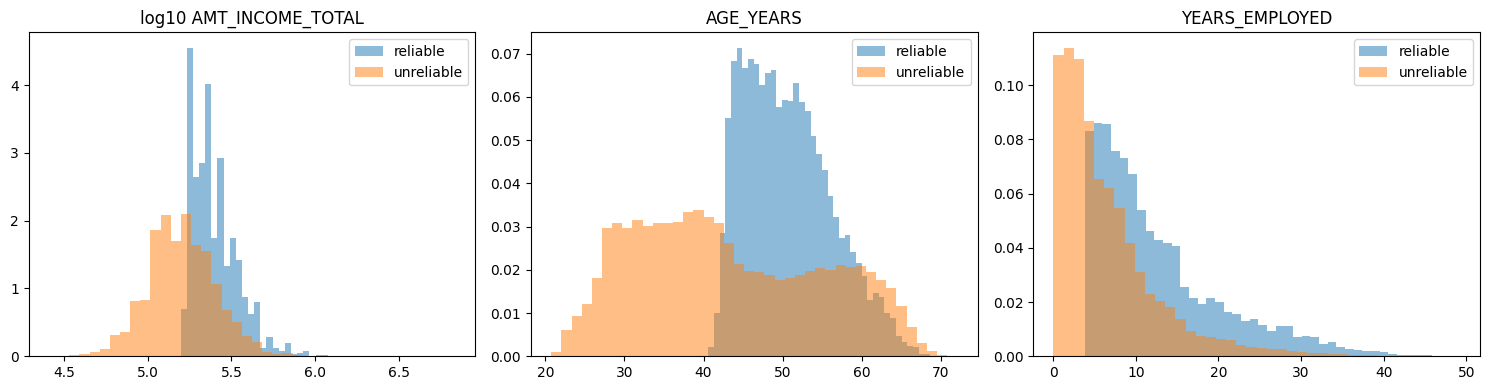

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var, log in zip(axes, ["AMT_INCOME_TOTAL", "AGE_YEARS", "YEARS_EMPLOYED"], [True, False, False]):
    for t, lab in [(1, "reliable"), (0, "unreliable")]:
        v = eda.loc[eda.TARGET == t, var].dropna()
        ax.hist(np.log10(v) if log else v, bins=40, density=True, alpha=0.5, label=lab)
    ax.set_title(("log10 " if log else "") + var); ax.legend()
plt.tight_layout(); plt.show()

In [101]:
base = eda["TARGET"].mean()
for col in ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_HOUSING_TYPE",
            "NAME_FAMILY_STATUS", "OCCUPATION_TYPE", "FLAG_OWN_REALTY", "FLAG_OWN_CAR"]:
    t = eda.groupby(col)["TARGET"].agg(n="size", rate="mean")
    t["lift"] = t["rate"] / base                      # >1: more reliable than average
    t["small sample"] = t["n"] < 500
    print(f"\n{col} (overall mean of the Train Target {base:.3f})")
    display(t.sort_values("rate", ascending=False).round(3))


NAME_INCOME_TYPE (overall mean of the Train Target 0.088)


,n,rate,lift,small sample
NAME_INCOME_TYPE,,,,
Student,8,0.250,2.846,True
State servant,16918,0.134,1.523,False
Commercial associate,46787,0.120,1.364,False
Working,104678,0.095,1.084,False
Pensioner,34664,0.000,0.000,False



NAME_EDUCATION_TYPE (overall mean of the Train Target 0.088)


,n,rate,lift,small sample
NAME_EDUCATION_TYPE,,,,
Academic degree,139,0.151,1.720,True
Higher education,54958,0.103,1.178,False
Secondary / secondary special,139316,0.084,0.953,False
Incomplete higher,6771,0.058,0.657,False
Lower secondary,1871,0.040,0.450,False



NAME_HOUSING_TYPE (overall mean of the Train Target 0.088)


,n,rate,lift,small sample
NAME_HOUSING_TYPE,,,,
Municipal apartment,6491,0.109,1.240,False
Office apartment,1742,0.094,1.072,False
House / apartment,182721,0.091,1.034,False
Co-op apartment,707,0.068,0.773,False
Rented apartment,2655,0.050,0.566,False
With parents,8739,0.022,0.251,False


... (4 outputs left out)


FLAG_OWN_REALTY (overall mean of the Train Target 0.088)


,n,rate,lift,small sample
FLAG_OWN_REALTY,,,,
Y,138647,0.093,1.063,False
N,64408,0.076,0.864,False



FLAG_OWN_CAR (overall mean of the Train Target 0.088)


,n,rate,lift,small sample
FLAG_OWN_CAR,,,,
Y,75217,0.101,1.154,False
N,127838,0.080,0.910,False


### Categorical variables vs Target

- **`NAME_INCOME_TYPE`**: consistent for State servant (lift 1.52), Commercial associate (1.36) and Working (1.08). **Pensioner has a rate of 0.000 on 34,664 records**, i.e. no reliable applicants: this is an anomaly (see below). Student (n=8) ignored.
- **`NAME_EDUCATION_TYPE`**: roughly monotonic order (Higher 0.103 → Secondary 0.084 → Lower secondary 0.040), with one unexplained inversion: Incomplete higher (0.058) is below Secondary. Academic degree is consistent but small (n=139).
- **`NAME_HOUSING_TYPE`**: consistent, With parents (0.022) and Rented (0.050) are the lowest, while House/Municipal/Office are above the mean; Co-op (0.068) is intermediate.
- **`NAME_FAMILY_STATUS`**: weak effect (lift 0.83-1.37); Separated and Widow above the mean, Single below. We had no strong expectation, but Separated at the top is not intuitive and may reflect age.
- **`OCCUPATION_TYPE`**: consistent at the top (Managers lift 2.03, Medicine, Accountants, High skill) and at the bottom (Waiters 0.024, Low-skill, Sales); Drivers and Laborers above the mean are not very intuitive. HR staff, Realty agents and IT staff are small and not interpretable.
- **`Missing` in `OCCUPATION_TYPE`**: 62,123 records, rate 0.044 (lift 0.50). Probably largely the same group as the pensioners; to be verified.
- **`FLAG_OWN_REALTY`**: consistent but weak (0.093 vs 0.076).
- **`FLAG_OWN_CAR`**: consistent but weak (0.101 vs 0.080).

In [102]:
display(pd.crosstab(eda["NAME_INCOME_TYPE"] == "Pensioner", eda["DAYS_EMPLOYED_ANOM"]))
display(pd.crosstab(eda["NAME_INCOME_TYPE"] == "Pensioner", eda["OCCUPATION_TYPE"] == "Missing"))
print("Rate without pensioners: ", eda.loc[eda["NAME_INCOME_TYPE"] != "Pensioner", "TARGET"].mean().round(3))   # rate without pensioners

DAYS_EMPLOYED_ANOM,0,1
NAME_INCOME_TYPE,,
False,168391,0
True,0,34664


OCCUPATION_TYPE,False,True
NAME_INCOME_TYPE,,
False,140932,27459
True,0,34664


Rate without pensioners:  0.106


In [103]:
mask_missing = eda["OCCUPATION_TYPE"] == "Missing"
mask_pens = eda["NAME_INCOME_TYPE"] == "Pensioner"
print("Missing, non-pensioners:", (mask_missing & ~mask_pens).sum(),
      " rate:", round(eda.loc[mask_missing & ~mask_pens, "TARGET"].mean(), 3))

Missing, non-pensioners: 27459  rate: 0.099


### Pensioners

**What emerges**
- All 34,664 pensioners (17% of the train set) have `TARGET = 0`: the rate of reliable applicants is 0.000 versus 0.088 overall. This is not a tendency but a deterministic rule.
- Pensioners coincide 100% with `DAYS_EMPLOYED_ANOM = 1` (positive values of `DAYS_EMPLOYED`) and with `OCCUPATION_TYPE = Missing`. The three pieces of information describe the same segment.
- Excluding the pensioners, the rate of reliable applicants rises from 0.088 to 0.106. This is an arithmetic effect (a zero-rate group is removed) and not evidence about the behaviour of pensioners.
- The "Missing" category of `OCCUPATION_TYPE` looks risky (0.044 on 62,123 records) only because it contains all the pensioners: the 27,459 non-pensioner "Missing" records have a rate of 0.099, in line with the average of non-pensioners (0.106). "Missing" is therefore not a risk signal in itself.

**Interpretation**
- In reality pensioners are never all unreliable. The target definition ("1 = pays instalments regularly") does not explain a 100% rate, so we treat it as an artefact of how the dataset was built, in line with the hypothesis that it is synthetic or heavily preprocessed.
- The segment can inflate the discrimination metrics (AUC, Gini, KS): one sixth of the records can be classified by a single rule, without any risk information.

**Limitation:** we cannot know whether the rule comes from the definition of the label or from the data generation; it is not interpreted as an economic cause.

**Choice:** `DAYS_EMPLOYED_ANOM` is removed from the features: it is redundant with the "Pensioner" category.


## Validation metrics

In [104]:
# keep_flag=False explicit, as decided in the previous analysis
lr  = Pipeline([("flags", FunctionTransformer(add_flags, kw_args={"keep_flag": False})), ("preprocessor", make_preprocessor(True)),
                ("model", LogisticRegression(solver="liblinear", random_state=SEED))]).fit(X_train, y_train)
gbm = Pipeline([("flags", FunctionTransformer(add_flags, kw_args={"keep_flag": False})), ("preprocessor", make_preprocessor(False)),
                ("model", LGBMClassifier(random_state=SEED, verbose=-1))]).fit(X_train, y_train)

In [105]:
def gini(y_true, score):
    return 2 * roc_auc_score(y_true, score) - 1

def ks_stat(y_true, score):
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.max(tpr - fpr))

def risk_report(name, y_true, score):
    return {"model": name, "AUC": roc_auc_score(y_true, score),
            "Gini": gini(y_true, score), "KS": ks_stat(y_true, score)}

In [106]:
mask_pens_val = X_val["NAME_INCOME_TYPE"] == "Pensioner"
print(f"Pensioners in validation: {mask_pens_val.sum()} ({mask_pens_val.mean():.1%})")

Pensioners in validation: 11490 (17.0%)


In [107]:
scores = {"Logistic Regression (v1-like)": lr.predict_proba(X_val)[:, 1],
          "LightGBM base": gbm.predict_proba(X_val)[:, 1]}

c:\Users\Tia\Desktop\ProfessionAI\Progetti\data-science-portfolio\[Data Science] credit_scoring_prediction\credit_scoring_venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [108]:
rows = []
for name, s in scores.items():
    s = pd.Series(s, index=X_val.index)
    for label, m in [("all", slice(None)), ("no pensioners", ~mask_pens_val)]:
        yy, ss = y_val[m], s[m]
        rows.append({"model": name, "population": label, "n": len(yy),
                     "reliable rate": round(yy.mean(), 3),
                     "AUC": roc_auc_score(yy, ss), "Gini": gini(yy, ss), "KS": ks_stat(yy, ss)})
pd.DataFrame(rows).round(3)

,model,population,n,reliable rate,AUC,Gini,KS
0,Logistic Regression (v1-like),all,67685,0.088,0.916,0.832,0.713
1,Logistic Regression (v1-like),no pensioners,56195,0.106,0.897,0.794,0.665
2,LightGBM base,all,67685,0.088,0.979,0.957,0.939
3,LightGBM base,no pensioners,56195,0.106,0.974,0.948,0.927


### Starting metrics (validation)

Gini and KS are reported both on the whole population and **excluding the pensioners**, to measure the discriminatory power of the other variables.


| Model | Population | Gini | KS |
|---|---|---|---|
| Logistic Regression (v1-like) | all / no pensioners | 0.832 / 0.794 | 0.713 / 0.665 |
| LightGBM base | all / no pensioners | 0.957 / 0.948 | 0.939 / 0.927 |

- Excluding the pensioners reduces the metrics only slightly (−0.04 Gini for the logistic regression, −0.01 for LightGBM): the discriminatory signal does not depend only on the deterministic segment.
- LightGBM outperforms the logistic regression by about 0.15 Gini: the logistic regression on raw variables does not capture interactions and non-linearities.
- The values (Gini ~0.95, KS ~0.93) are much higher than those of a real portfolio and are consistent with a synthetic dataset: they must not be read as expected production performance.
- The values on validation match those of v1 on the test set (AUC 0.979 and 0.918): the selection bias inherited from v1 is negligible.

In [109]:
from sklearn.tree import DecisionTreeClassifier
for d in [2, 3, 5]:
    t = Pipeline([("flags", FunctionTransformer(add_flags)), ("prep", make_preprocessor(False)),
                  ("m", DecisionTreeClassifier(max_depth=d, random_state=SEED))]).fit(X_train, y_train)
    print(f"Decision Tree with max depth: {d}, Gini: {round(gini(y_val, t.predict_proba(X_val)[:, 1]), 3)}")

Decision Tree with max depth: 2, Gini: 0.82
Decision Tree with max depth: 3, Gini: 0.931
Decision Tree with max depth: 5, Gini: 0.956


In [110]:
t3 = Pipeline([("flags", FunctionTransformer(add_flags)), ("prep", make_preprocessor(False)),
               ("m", DecisionTreeClassifier(max_depth=3, random_state=SEED))]).fit(X_train, y_train)
from sklearn.tree import export_text
names = list(t3.named_steps["prep"].get_feature_names_out())
print(export_text(t3.named_steps["m"], feature_names=names))

|--- num__AMT_INCOME_TOTAL <= 164805.88
|   |--- num__AMT_INCOME_TOTAL <= 162662.41
|   |   |--- num__AMT_INCOME_TOTAL <= 159945.45
|   |   |   |--- class: 0
|   |   |--- num__AMT_INCOME_TOTAL >  159945.45
|   |   |   |--- class: 0
|   |--- num__AMT_INCOME_TOTAL >  162662.41
|   |   |--- num__DAYS_EMPLOYED <= -4959.50
|   |   |   |--- class: 0
|   |   |--- num__DAYS_EMPLOYED >  -4959.50
|   |   |   |--- class: 0
|--- num__AMT_INCOME_TOTAL >  164805.88
|   |--- num__DAYS_BIRTH <= -15545.50
|   |   |--- num__DAYS_EMPLOYED <= -1944.50
|   |   |   |--- class: 1
|   |   |--- num__DAYS_EMPLOYED >  -1944.50
|   |   |   |--- class: 0
|   |--- num__DAYS_BIRTH >  -15545.50
|   |   |--- num__DAYS_BIRTH <= -15201.50
|   |   |   |--- class: 0
|   |   |--- num__DAYS_BIRTH >  -15201.50
|   |   |   |--- class: 0



### Inspection of the thresholds of a simple Decision Tree

Prediction of reliable (class 1) if:
- income > ~165,000 and
- age > ~42.6 years (DAYS_BIRTH ≤ −15,545) and
- length of employment > ~5.3 years (DAYS_EMPLOYED ≤ −1,944)

All the other branches are class 0. The thresholds around 160-165 thousand on income in the left branch (162,662, 159,945) are the tree's attempt to refine the same threshold: read properly, it is a single threshold on income of about 165 thousand.

Consequences:
- The label seems to be built from a rule with three conditions in AND. This explains Gini 0.93 at depth 3 and the KS of 0.93 of LightGBM: the models are reconstructing the rule.
- It explains the pensioners. For them DAYS_EMPLOYED is anomalous (it becomes NaN), so they cannot satisfy “employment > 5.3 years”: zero reliable applicants by construction. Consistent with the hypothesis that the label requires an employment history; it remains a hypothesis, because the original rule cannot be seen from the tree.

## Binning and WoE

**Choice**:
- **Exclusion of `CODE_GENDER`.** Gender is a protected attribute. For the scorecard we exclude it as a precautionary choice, instead of carrying out a full fairness analysis, which is outside the scope of the project. Age is kept among the candidates because it appears in the structure of the label, but it must be read with caution because it is also a sensitive attribute in a real context.
- The scorecard is built on the population without pensioners; pensioners are treated as a segment with an exclusion rule (knock-out), as a real credit process would do.

In [111]:
def scorecard_pop(X, y):
    m = X["NAME_INCOME_TYPE"] != "Pensioner"
    Xs = add_flags(X.loc[m]).drop(columns=["CODE_GENDER"])
    ys_bad = (1 - y.loc[m]).rename("BAD")          # 1 = unreliable (event), 0 = reliable (non-event)
    return Xs, ys_bad

Xs_train, yb_train = scorecard_pop(X_train, y_train)
Xs_val,   yb_val   = scorecard_pop(X_val,   y_val)
Xs_test,  yb_test  = scorecard_pop(X_test,  y_test)

print("Set sizes without the pensioners")
print("Train: ", len(Xs_train), "Validation: ", len(Xs_val), "Test: ", len(Xs_test))
print("Share of bad (unreliable) in the train set:", round(yb_train.mean(), 3))

Set sizes without the pensioners
Train:  168391 Validation:  56195 Test:  55999
Share of bad (unreliable) in the train set: 0.894


In [112]:
text_cols_s = list(Xs_train.select_dtypes("object").columns)
bin_cols_s  = [c for c in Xs_train.columns if c not in text_cols_s and set(Xs_train[c].dropna().unique()) <= {0, 1}]
num_cols_s  = [c for c in Xs_train.columns if c not in text_cols_s + bin_cols_s]
categorical = text_cols_s + bin_cols_s

bp = BinningProcess(variable_names=list(Xs_train.columns),
                    categorical_variables=categorical,
                    max_n_bins=6, min_bin_size=0.03)       # declared parameters, not optimised
bp.fit(Xs_train, yb_train)

bp.summary().sort_values("iv", ascending=False)

,name,dtype,status,selected,n_bins,iv,js,gini,quality_score
3,AMT_INCOME_TOTAL,numerical,OPTIMAL,True,6,4.788728,0.223877,0.553445,0.0
8,DAYS_BIRTH,numerical,OPTIMAL,True,6,4.30905,0.293306,0.678443,0.0
9,DAYS_EMPLOYED,numerical,OPTIMAL,True,6,2.228604,0.184639,0.547517,0.000001
2,CNT_CHILDREN,numerical,OPTIMAL,True,3,0.277729,0.033364,0.228166,0.709131
14,CNT_FAM_MEMBERS,numerical,OPTIMAL,True,4,0.25054,0.030057,0.208851,0.328379
13,OCCUPATION_TYPE,categorical,OPTIMAL,True,6,0.094277,0.011633,0.156407,0.310625
7,NAME_HOUSING_TYPE,categorical,OPTIMAL,True,2,0.076839,0.008942,0.053742,0.077761
6,NAME_FAMILY_STATUS,categorical,OPTIMAL,True,4,0.041724,0.005164,0.086074,0.109325
10,FLAG_WORK_PHONE,categorical,OPTIMAL,True,2,0.027461,0.003422,0.069239,0.086647
4,NAME_INCOME_TYPE,categorical,OPTIMAL,True,3,0.021913,0.002735,0.074574,0.071957


In [113]:
for v in ["AMT_INCOME_TOTAL", "DAYS_BIRTH", "DAYS_EMPLOYED", "NAME_EDUCATION_TYPE"]:
    ov = bp.get_binned_variable(v)
    print(f"\n=== {v} ===")
    display(ov.binning_table.build())


=== AMT_INCOME_TOTAL ===


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 157812.50)",71290,0.423360,1,71289,0.999986,-9.041262,4.280546,0.163841
1,"[157812.50, 164805.88)",8420,0.050003,108,8312,0.987173,-2.210089,0.108631,0.011352
2,"[164805.88, 180632.91)",12273,0.072884,2110,10163,0.828078,0.561169,0.028513,0.003518
3,"[180632.91, 258791.99)",44079,0.261766,8516,35563,0.806801,0.703876,0.169849,0.020803
4,"[258791.99, 315565.23)",15884,0.094328,3268,12616,0.794258,0.782447,0.077814,0.009486
5,"[315565.23, inf)",16445,0.097660,3831,12614,0.767042,0.941554,0.123374,0.014876
6,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
7,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,168391,1.000000,17834,150557,0.894092,,4.788728,0.223877



=== DAYS_BIRTH ===


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -20288.50)",11610,0.068947,3476,8134,0.700603,1.283064,0.180761,0.021163
1,"[-20288.50, -17453.50)",30469,0.180942,7934,22535,0.739604,1.089323,0.321571,0.038320
2,"[-17453.50, -16194.50)",16329,0.096971,4142,12187,0.746341,1.054044,0.159484,0.019061
3,"[-16194.50, -15637.50)",8573,0.050911,1722,6851,0.799137,0.752327,0.038408,0.004691
4,"[-15637.50, -15115.50)",8422,0.050015,528,7894,0.937307,-0.571527,0.013045,0.001609
5,"[-15115.50, inf)",92988,0.552215,32,92956,0.999656,-5.840911,3.595780,0.208463
6,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
7,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,168391,1.000000,17834,150557,0.894092,,4.309050,0.293306



=== DAYS_EMPLOYED ===


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, -7703.50)",8430,0.050062,2682,5748,0.681851,1.370946,0.153832,0.017852
1,"[-7703.50, -5086.50)",13798,0.081940,3247,10551,0.764676,0.954746,0.106920,0.012879
2,"[-5086.50, -3936.50)",12895,0.076578,2511,10384,0.805273,0.71365,0.051260,0.006275
3,"[-3936.50, -3268.50)",12046,0.071536,2059,9987,0.829072,0.554171,0.027221,0.003360
4,"[-3268.50, -1511.50)",53271,0.316353,7214,46057,0.864579,0.279379,0.027546,0.003432
5,"[-1511.50, inf)",67951,0.403531,121,67830,0.998219,-4.195734,1.861825,0.140841
6,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
7,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,168391,1.000000,17834,150557,0.894092,,2.228604,0.184639



=== NAME_EDUCATION_TYPE ===


,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"[Academic degree, Higher education]",49378,0.293234,5705,43673,0.884463,0.097848,0.002918,0.000365
1,"[Secondary / secondary special, Lower secondar...",119013,0.706766,12129,106884,0.898087,-0.04291,0.001280,0.000160
2,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
3,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,168391,1.000000,17834,150557,0.894092,,0.004197,0.000524


In [114]:
for v in ["AMT_INCOME_TOTAL", "DAYS_BIRTH", "DAYS_EMPLOYED"]:
    name_file = f"binning_table_{v}.png"
    path_file = os.path.join("results_v2", name_file)
    bp.get_binned_variable(v).binning_table.plot(metric="woe", savefig=path_file)

In [115]:
def knockout(X):
    return ((X["AMT_INCOME_TOTAL"] < 157812.5) | (X["DAYS_BIRTH"] > -15115.5) | (X["DAYS_EMPLOYED"] > -1511.5))

for set_name, X_, yb_ in [("train", Xs_train, yb_train), ("validation", Xs_val, yb_val)]:
    ko = knockout(X_)
    good = (yb_ == 0)
    print(f"{set_name}: excluded {ko.mean():.1%} of the clients, "
          f"reliable applicants lost {(ko & good).sum()} out of {good.sum()} ({(ko & good).sum()/good.sum():.1%}); "
          f"remaining {(~ko).sum()} clients, share of bad {yb_[~ko].mean():.3f}")

train: excluded 81.7% of the clients, reliable applicants lost 153 out of 17834 (0.9%); remaining 30876 clients, share of bad 0.427
validation: excluded 81.8% of the clients, reliable applicants lost 55 out of 5944 (0.9%); remaining 10221 clients, share of bad 0.424


### Binning and Information Value

**Population.** After excluding the pensioners, 168,391 clients remain in the train set, 56,195 in validation and 55,999 in the test set, with a share of unreliable applicants ("bad", the event) of 0.894 in the train set. For the binning the target is `BAD = 1 − TARGET`, so that a higher WoE indicates better clients. `CODE_GENDER` was excluded as a precautionary choice (protected attribute).

**Information Value.** Three variables have an IV far above the norm: `AMT_INCOME_TOTAL` (4.79), `DAYS_BIRTH` (4.31) and `DAYS_EMPLOYED` (2.23). In practice an IV above 0.5 is already a warning sign. They are followed by `CNT_CHILDREN` (0.28) and `CNT_FAM_MEMBERS` (0.25), `OCCUPATION_TYPE` (0.094), `NAME_HOUSING_TYPE` (0.077), `NAME_FAMILY_STATUS` (0.042), `FLAG_WORK_PHONE` (0.027), `NAME_INCOME_TYPE` (0.022). Below the 0.02 threshold: `FLAG_OWN_REALTY` (0.019), `NAME_EDUCATION_TYPE` (0.004), `FLAG_PHONE`, `FLAG_OWN_CAR`, `FLAG_EMAIL`. For `NAME_EDUCATION_TYPE` the effect observed in the EDA disappears once the pensioners are excluded.

**WoE trend.** For income, age and length of employment the WoE is monotonic and consistent with expectations: it increases with income (from −9.04 to +0.94), with age and with length of employment.

**Why the IVs are so high: near-absolute thresholds.**
- Income < 157,812: 71,290 clients (42%), only **1** reliable applicant.
- Age < ~41.4 years (`DAYS_BIRTH` > −15,115): 92,988 clients (55%), **32** reliable applicants.
- Length of employment < ~4.1 years (`DAYS_EMPLOYED` > −1,511): 67,951 clients (40%), **121** reliable applicants.

These are almost necessary but not sufficient conditions: above the thresholds the share of unreliable applicants stays between 0.77 and 0.83. The WoE of −9.04 of the first class depends on a single record and is unstable. In a real portfolio these would be exclusion rules (knock-out) of the credit policy, not score classes.

**Knock-out check (thresholds derived from the train set).** The three rules exclude 81.7% of the clients in the train set (81.8% in validation) and lose only 153 reliable applicants out of 17,834 (0.9%; in validation 55 out of 5,944). The remaining population is 30,876 clients in the train set and 10,221 in validation, with a share of unreliable applicants of 0.427 and 0.424: much more balanced than the starting population.

**Methodological choice.**
- **Scorecard B (official):** built on the remaining population after the pensioner filter and the knock-out rules, so that pensioners and the three thresholds are handled as exclusion rules, as in a real credit process.
- **Scorecard A (control):** built on the population without pensioners (filtered here as well), without applying the knock-out rules, to check how much the results depend on the thresholds. By construction it will show extreme WoE values and scores dominated by the three variables.

**Limitations.** The thresholds are derived from the train labels and not from a real policy; the dataset is probably synthetic and the metrics must not be interpreted as expected performance on real data.

### Population B

In [116]:
Xb_train, yb_b_train = Xs_train[~knockout(Xs_train)], yb_train[~knockout(Xs_train)]
Xb_val,   yb_b_val   = Xs_val[~knockout(Xs_val)],     yb_val[~knockout(Xs_val)]

print("Correlation CNT_CHILDREN / CNT_FAM_MEMBERS (train, Population A):",
      round(Xs_train["CNT_CHILDREN"].corr(Xs_train["CNT_FAM_MEMBERS"]), 3))
print("Population B:\n", "Train: ", len(Xb_train), "Validation: ", len(Xb_val))

Correlation CNT_CHILDREN / CNT_FAM_MEMBERS (train, Population A): 0.9
Population B:
 Train:  30876 Validation:  10221


## Scorecard

In [117]:
DROP = ["CNT_FAM_MEMBERS"]       # collinearity with CNT_CHILDREN (see correlation)

def build_scorecard(Xtr, ybtr):
    Xtr = Xtr.drop(columns=DROP)
    cats = [c for c in Xtr.columns if c in categorical]
    bp = BinningProcess(variable_names=list(Xtr.columns), categorical_variables=cats,
                        max_n_bins=6, min_bin_size=0.03,
                        selection_criteria={"iv": {"min": 0.02}})
    sc = Scorecard(binning_process=bp,
                   estimator=LogisticRegression(solver="lbfgs", max_iter=1000, random_state=SEED),
                   scaling_method="min_max", scaling_method_params={"min": 300, "max": 850})
    return sc.fit(Xtr, ybtr)

sc_A = build_scorecard(Xs_train, yb_train)       # control
sc_B = build_scorecard(Xb_train, yb_b_train)     # official

display(sc_B.table(style="summary"))

,Variable,Bin,Points
0,CNT_CHILDREN,"(-inf, 0.50)",267.073214
1,CNT_CHILDREN,"[0.50, inf)",259.562479
2,CNT_CHILDREN,Special,265.565472
3,CNT_CHILDREN,Missing,265.565472
0,AMT_INCOME_TOTAL,"(-inf, 164840.19)",-13.872389
1,AMT_INCOME_TOTAL,"[164840.19, 180544.64)",269.093617
2,AMT_INCOME_TOTAL,"[180544.64, 216610.32)",280.580982
3,AMT_INCOME_TOTAL,"[216610.32, 258734.91)",282.382539
4,AMT_INCOME_TOTAL,"[258734.91, 317867.81)",283.706619
5,AMT_INCOME_TOTAL,"[317867.81, inf)",287.191106


### Evaluation on validation

In [118]:
def eval_on(idx, sc, X_sc, name):
    y_good = y_val.loc[idx]                             # 1 = reliable
    s_sc = sc.score(X_sc.drop(columns=DROP))            # scorecard score
    if roc_auc_score(y_good, s_sc) < 0.5:
        print(f"WARNING: {name} has inverted direction, use -score")
        s_sc = -s_sc
    rows = [risk_report(f"Scorecard {name}", y_good, s_sc),
            risk_report("Logistic Regression (v1-like)", y_good, lr.predict_proba(X_val.loc[idx])[:, 1]),
            risk_report("LightGBM base", y_good, gbm.predict_proba(X_val.loc[idx])[:, 1])]
    out = pd.DataFrame(rows).round(3)
    out.insert(1, "population", name)
    out.insert(2, "n", len(idx))
    return out

res = pd.concat([eval_on(Xs_val.index, sc_A, Xs_val, "A (no pensioners)"),
                 eval_on(Xb_val.index, sc_B, Xb_val, "B (no pensioners, no knock-out)")])
res

c:\Users\Tia\Desktop\ProfessionAI\Progetti\data-science-portfolio\[Data Science] credit_scoring_prediction\credit_scoring_venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\Tia\Desktop\ProfessionAI\Progetti\data-science-portfolio\[Data Science] credit_scoring_prediction\credit_scoring_venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,population,n,AUC,Gini,KS
0,Scorecard A (no pensioners),A (no pensioners),56195,0.973,0.945,0.915
1,Logistic Regression (v1-like),A (no pensioners),56195,0.897,0.794,0.665
2,LightGBM base,A (no pensioners),56195,0.974,0.948,0.927
0,"Scorecard B (no pensioners, no knock-out)","B (no pensioners, no knock-out)",10221,0.705,0.409,0.366
1,Logistic Regression (v1-like),"B (no pensioners, no knock-out)",10221,0.615,0.231,0.178
2,LightGBM base,"B (no pensioners, no knock-out)",10221,0.701,0.402,0.377


### Scorecard results (validation)

| Population | Model | Gini | KS |
|---|---|---|---|
| A (no pensioners) | Scorecard A | 0.945 | 0.915 |
| A | Logistic Regression (v1-like) | 0.794 | 0.665 |
| A | LightGBM base | 0.948 | 0.927 |
| B (no pensioners, no knock-out) | Scorecard B | 0.409 | 0.366 |
| B | Logistic Regression (v1-like) | 0.231 | 0.178 |
| B | LightGBM base | 0.402 | 0.377 |

- **Population A (control).** The scorecard with WoE practically reaches the Gini of LightGBM (0.945 vs 0.948) and exceeds the logistic regression on raw variables by about 0.15: the binning captures the thresholds on the single variables, which explain almost the whole label. The value depends largely on the three thresholds on income, age and length of employment and must not be read as discriminatory power on real data.
- **Population B (official scorecard).** After excluding the pensioners and the three knock-out rules, the Gini drops to 0.409 (KS 0.366): values much closer to those of a real portfolio. The scorecard (0.409) and LightGBM (0.402) are equivalent within the sampling uncertainty (10,221 clients).
- **Residual thresholds.** In population B there are still classes with very low scores for income below ~165,000 and for age just above the exclusion threshold, a sign that the knock-out rules extracted from the binning (157,812; 41.4 years; 4.1 years of employment) are conservative: they do not remove the whole threshold structure of the three variables.
- **Limitation of the comparison.** The logistic regression and LightGBM are trained on the full population; a fairer comparison in B requires models trained on the remaining population (see next section).
- **Score.** The 300-850 scale is a display convention; the points per class are those in the table of scorecard B.

### Comparison with models trained on the filtered set

In [119]:
def make_prep_from(X, scale=False):
    t = list(X.select_dtypes("object").columns)
    b = [c for c in X.columns if c not in t and set(X[c].dropna().unique()) <= {0, 1}]
    n = [c for c in X.columns if c not in t + b]
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(num_steps), n),
                              ("txt", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                                                ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]), t),
                              ("bin", "passthrough", b)])

Xc_tr, Xc_val = Xb_train.drop(columns=DROP), Xb_val.drop(columns=DROP)
yg_tr, yg_val = 1 - yb_b_train, 1 - yb_b_val          # 1 = reliable

lr_B  = Pipeline([("prep", make_prep_from(Xc_tr, True)),  ("m", LogisticRegression(solver="liblinear", random_state=SEED))]).fit(Xc_tr, yg_tr)
gbm_B = Pipeline([("prep", make_prep_from(Xc_tr, False)), ("m", LGBMClassifier(random_state=SEED, verbose=-1))]).fit(Xc_tr, yg_tr)

display(pd.DataFrame([risk_report("Logistic Regression trained on B", yg_val, lr_B.predict_proba(Xc_val)[:, 1]),
              risk_report("LightGBM trained on B", yg_val, gbm_B.predict_proba(Xc_val)[:, 1])]).round(3))

# which variables carry the signal in population B (IV and univariate Gini)
sc_B.binning_process_.summary().sort_values("iv", ascending=False)

c:\Users\Tia\Desktop\ProfessionAI\Progetti\data-science-portfolio\[Data Science] credit_scoring_prediction\credit_scoring_venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,AUC,Gini,KS
0,Logistic Regression trained on B,0.625,0.251,0.202
1,LightGBM trained on B,0.704,0.407,0.375


,name,dtype,status,selected,n_bins,iv,js,gini,quality_score
3,AMT_INCOME_TOTAL,numerical,OPTIMAL,True,6,0.621007,0.055398,0.198549,0.08006
8,DAYS_BIRTH,numerical,OPTIMAL,True,6,0.484302,0.051579,0.244586,0.604123
2,CNT_CHILDREN,numerical,OPTIMAL,True,2,0.028957,0.003605,0.068079,0.076202
9,DAYS_EMPLOYED,numerical,OPTIMAL,False,6,0.010137,0.001264,0.047506,0.030833
13,OCCUPATION_TYPE,categorical,OPTIMAL,False,6,0.004782,0.000598,0.038886,0.000508
6,NAME_FAMILY_STATUS,categorical,OPTIMAL,False,4,0.002553,0.000319,0.01915,0.000567
12,FLAG_EMAIL,categorical,OPTIMAL,False,2,0.001965,0.000245,0.014132,0.003357
10,FLAG_WORK_PHONE,categorical,OPTIMAL,False,2,0.001528,0.000191,0.015643,0.004059
5,NAME_EDUCATION_TYPE,categorical,OPTIMAL,False,2,0.001319,0.000165,0.016821,0.004718
4,NAME_INCOME_TYPE,categorical,OPTIMAL,False,3,0.000969,0.000121,0.015737,0.000673


### Fair comparison in population B (models trained on the remaining population)

| Model | AUC | Gini | KS |
|---|---|---|---|
| Logistic Regression on raw variables | 0.625 | 0.251 | 0.202 |
| LightGBM | 0.704 | 0.407 | 0.375 |
| Scorecard B | 0.705 | 0.409 | 0.366 |

- Scorecard B and LightGBM are equivalent (Gini difference of 0.002, within the sampling uncertainty): in the remaining population, a model free to capture interactions finds no signal beyond what the scorecard captures by summing the effects per class of income, age and number of children.
- The logistic regression on raw variables loses about 0.16 Gini compared with the scorecard: the effect of income and age is threshold-based and not linear, and the WoE binning recovers it while keeping the model interpretable.
- Training LightGBM on the remaining population instead of the full one does not change its performance in B (0.407 vs 0.402).

### Variables of scorecard B (IV in the remaining population)

In population B (no pensioners, no knock-out) three variables exceed the IV ≥ 0.02 threshold, set before the analysis: `AMT_INCOME_TOTAL` (IV 0.621; univariate Gini 0.199), `DAYS_BIRTH` (0.484; 0.245) and `CNT_CHILDREN` (0.029; 0.068). All the others have IV < 0.011; `DAYS_EMPLOYED` (0.010) is just below the threshold and is not reintroduced a posteriori.

- The Gini of scorecard B (0.409) is therefore driven by income and age, through the residual thresholds already observed in the points table (income ~165,000; age just above 42 years).
- The variables with a non-negligible IV in population A (occupation, housing, number of children) lose almost all their signal in B: they were largely proxies of the three variables behind the knock-out rules (for example, people living with their parents are on average younger).
- Length of employment adds no information beyond the exclusion threshold.

**Limitation.** The dataset offers very little signal beyond income and age in the grey zone: the residual discriminatory capacity is not representative of a real portfolio.

### Score acceptance cut-off with declared cost

In [120]:
s_val = pd.Series(sc_B.score(Xb_val.drop(columns=DROP)), index=Xb_val.index)
if roc_auc_score(yg_val, s_val) < 0.5:
    s_val = -s_val

def profit_curve(s, y_good, ratio, gain=100, n_grid=300):
    cuts = np.append(np.quantile(s, np.linspace(0, 0.99, n_grid)), s.max() + 1)
    rows = []
    for c in cuts:
        a = s >= c
        g, b = (a & (y_good == 1)).sum(), (a & (y_good == 0)).sum()
        rows.append({"cut-off": c, "approval rate": a.mean(),
                     "unreliable share among approved": b / max(a.sum(), 1),
                     "profit per applicant": (gain * g - gain * ratio * b) / len(s)})
    return pd.DataFrame(rows)

best = []
for R in [1, 2, 3, 5, 10]:
    pc = profit_curve(s_val, yg_val, R)
    r = pc.loc[pc["profit per applicant"].idxmax()]
    best.append({"R = loss/gain": R, **r.round(3).to_dict()})
pd.DataFrame(best)

,R = loss/gain,cut-off,approval rate,unreliable share among approved,profit per applicant
0,1,777.180,0.795,0.313,29.792
1,2,829.365,0.614,0.296,6.956
2,3,851.000,0.000,0.000,0.000
3,5,851.000,0.000,0.000,0.000
4,10,851.000,0.000,0.000,0.000


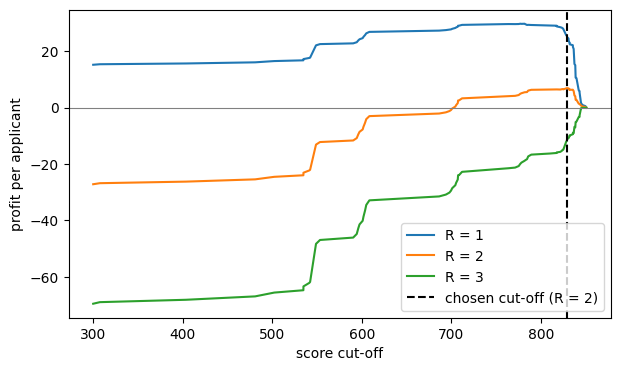

<Figure size 640x480 with 0 Axes>

In [121]:
plt.figure(figsize=(7, 4))
for R in [1, 2, 3]:
    pc = profit_curve(s_val, yg_val, R)
    plt.plot(pc["cut-off"], pc["profit per applicant"], label=f"R = {R}")
plt.axhline(0, color="grey", lw=0.8)
plt.axvline(829.365, color="k", ls="--", label="chosen cut-off (R = 2)")
plt.xlabel("score cut-off"); plt.ylabel("profit per applicant"); plt.legend(); plt.show()

plt.savefig("results_v2/profit_vs_cutoff.png", dpi=150, bbox_inches="tight")

plt.show()

In [122]:
base_bad = yb_b_val.mean()
for R in [1, 2, 3]:
    print("R =", R, "if everyone is approved -> profit per applicant =", round(100 * (1 - base_bad) - 100 * R * base_bad, 1))

R = 1 if everyone is approved -> profit per applicant = 15.2
R = 2 if everyone is approved -> profit per applicant = -27.1
R = 3 if everyone is approved -> profit per applicant = -69.5


### Choice of the acceptance cut-off (population B, validation)

**Economic assumptions (declared, not estimated from the data).** An approved reliable applicant yields +100; an approved unreliable applicant yields −100·R; a rejected applicant yields 0. R (loss/gain ratio) is a sensitivity parameter. The cut-off is chosen on validation; the test set is not used.

| R | Cut-off (points) | Approval rate | Unreliable among approved | Profit per applicant |
|---|---|---|---|---|
| 1 | 777.2 | 79.5% | 31.3% | 29.8 |
| 2 | 829.4 | 61.4% | 29.6% | 7.0 |
| ≥ 3 | no profitable cut-off | 0% | – | 0 |

**Reading.**
- For R ≥ 3 there is no cut-off with a positive profit: the optimal choice is therefore not to approve.
- For comparison, approving all the clients of population B would give a profit per applicant of about 15 with R = 1 and negative (about −27) with R = 2: at R = 2 the scorecard turns a loss-making policy into a profitable one.
- **R = 2** is taken as the reference scenario, i.e. the last level of R for which the cut-off has a positive profit, with a **cut-off** of **829.4 points**. This choice was made after observing the sensitivities (the central scenario originally planned, R = 3, turns out to be unprofitable) and must not be read as an estimate of the real loss.
- Taking the knock-out rules into account (81.8% of the applicants excluded, with a loss of less than 1% of the reliable ones), the R = 2 cut-off approves about 11% of the non-pensioner applicants.

**Limitations.** The economic figures are assumptions; the dataset is probably synthetic; the Gini in the grey zone is moderate (0.41), so the trade-off between approval rate and risk remains tight.


## PSI (score stability)

In [123]:
def psi(expected, actual, bins=10):
    q = np.quantile(expected, np.linspace(0, 1, bins + 1)); q[0], q[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, q)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, q)[0] / len(actual), 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

s_tr = sc_B.score(Xb_train.drop(columns=DROP))
print("PSI train vs validation:", round(psi(s_tr, s_val.values), 4))

PSI train vs validation: 0.001


The PSI between train and validation is 0.001 (conventional stability threshold: 0.1). The value is expected because the two sets come from a random split of the same dataset, which has no time dimension: it is a consistency check and not monitoring over time. An out-of-time (OOT) analysis would be needed.

## Final evaluation on the test set

**Final evaluation on the test set.** Model (scorecard B), variables, binning and cut-off (829.4 points, scenario R = 2) were fixed on validation. The test set is used only once and the results are reported without further changes.

In [124]:
CUT, R_REF = 829.365, 2        # fixed on validation

Xb_test = Xs_test[~knockout(Xs_test)]
yg_test = 1 - yb_test.loc[Xb_test.index]
s_test = pd.Series(sc_B.score(Xb_test.drop(columns=DROP)), index=Xb_test.index)
if roc_auc_score(yg_test, s_test) < 0.5:
    s_test = -s_test

print("Test B:", len(Xb_test), "clients; share of unreliable", round(1 - yg_test.mean(), 3))
display(pd.DataFrame([risk_report("Scorecard B", yg_test, s_test)]).round(3))

a = s_test >= CUT
g, b = (a & (yg_test == 1)).sum(), (a & (yg_test == 0)).sum()
print(f"Approved: {a.mean():.1%}  unreliable among approved: {b / a.sum():.3f}")
print("Profit per applicant (R=2):", round((100 * g - 100 * R_REF * b) / len(yg_test), 2),
      " | approve everyone:", round(100 * (1 - (1 - yg_test.mean())) - 100 * R_REF * (1 - yg_test.mean()), 2))

Test B: 10342 clients; share of unreliable 0.431


,model,AUC,Gini,KS
0,Scorecard B,0.702,0.404,0.356


Approved: 61.6%  unreliable among approved: 0.306
Profit per applicant (R=2): 4.97  | approve everyone: -29.26


### Final evaluation on the test set (scorecard B, cut-off 829.4, R = 2)

| Metric | Validation | Test |
|---|---|---|
| Clients (population B) | 10,221 | 10,342 |
| Gini | 0.409 | 0.404 |
| KS | 0.366 | 0.356 |
| AUC | 0.705 | 0.702 |
| Approval rate | 61.4% | 61.6% |
| Unreliable among approved | 29.6% | 30.6% |
| Profit per applicant (R = 2) | 6.96 | 4.97 |
| Profit "approve everyone" (R = 2) | about −27 | −29.26 |

- The ranking metrics on the test set are in line with validation (differences of 0.005-0.01), so there are no signs of overfitting due to the choices made on validation.
- The profit is a thin margin: with R = 2 break-even corresponds to 33.3% of unreliable applicants among the approved, and on the test set the share is 30.6%. The value must be read as an order of magnitude and depends on the economic assumptions, not as an estimate of the real profit.
- The comparison with indiscriminate approval remains clear-cut: the scorecard turns a loss-making policy (−29.26) into a profitable one (+4.97), under the declared assumptions.
- Scorecard A (control) was evaluated on validation only.